<a href="https://colab.research.google.com/github/justleein2/MachineLearning/blob/main/HW5/diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Task 1:

In [99]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cols = ['Pregnancy_Count','Glucone_conc','Blood_pressure','Skin_thickness','Insulin','BMI','DPF','Age','Class','Outcome']

df = pd.read_csv('Diabetes.csv', skiprows= 9, names= cols, na_values= "?", header= None)

Task 2:

In [100]:
print(df.head())
print("\n....Describe....")

display(df.describe())
print("\n....Info....")

print(df.info())

   Pregnancy_Count  Glucone_conc  Blood_pressure  Skin_thickness  Insulin  \
0                6           148              72              35        0   
1                1            85              66              29        0   
2                8           183              64               0        0   
3                1            89              66              23       94   
4                0           137              40              35      168   

    BMI    DPF  Age  Class  Outcome  
0  33.6  0.627   50      1      NaN  
1  26.6  0.351   31      0      NaN  
2  23.3  0.672   32      1      NaN  
3  28.1  0.167   21      0      NaN  
4  43.1  2.288   33      1      NaN  

....Describe....


,Pregnancy_Count,Glucone_conc,Blood_pressure,Skin_thickness,Insulin,BMI,DPF,Age,Class,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,0.0
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958,NaN
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951,NaN
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000,NaN
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000,NaN
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000,NaN
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000,NaN
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000,NaN



....Info....
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Pregnancy_Count  768 non-null    int64  
 1   Glucone_conc     768 non-null    int64  
 2   Blood_pressure   768 non-null    int64  
 3   Skin_thickness   768 non-null    int64  
 4   Insulin          768 non-null    int64  
 5   BMI              768 non-null    float64
 6   DPF              768 non-null    float64
 7   Age              768 non-null    int64  
 8   Class            768 non-null    int64  
 9   Outcome          0 non-null      float64
dtypes: float64(3), int64(7)
memory usage: 60.1 KB
None


In [101]:
print(df.columns.tolist())
print(df.shape)

placeholder_cols = ['Glucone_conc','Blood_pressure','Skin_thickness','Insulin','BMI']
print((df[placeholder_cols] == 0).sum())

df[placeholder_cols] = df[placeholder_cols].replace(0, np.nan)
print((df[placeholder_cols] == 0).sum())

df["Outcome"] = df["Outcome"].replace(np.nan, 0)


['Pregnancy_Count', 'Glucone_conc', 'Blood_pressure', 'Skin_thickness', 'Insulin', 'BMI', 'DPF', 'Age', 'Class', 'Outcome']
(768, 10)
Glucone_conc        5
Blood_pressure     35
Skin_thickness    227
Insulin           374
BMI                11
dtype: int64
Glucone_conc      0
Blood_pressure    0
Skin_thickness    0
Insulin           0
BMI               0
dtype: int64


Task 3:

In [102]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

df.isnull().sum()

imputer = SimpleImputer(strategy="median")
df[placeholder_cols] = imputer.fit_transform(df[placeholder_cols])


Task 4:

In [103]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

X = df.drop(columns="Outcome")
y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

preprocessor = ColumnTransformer(
    [("scaler", StandardScaler(), X.columns.tolist())])

def make_pipe(model):
    return Pipeline([("preprocessor", preprocessor), ("model", model)])

Task 5: Voting

In [104]:
# bug fix check

print("y overall:", y.value_counts(dropna=False).to_dict())
print("y_train  :", y_train.value_counts(dropna=False).to_dict())
print("y_test   :", y_test.value_counts(dropna=False).to_dict())

y overall: {0.0: 768}
y_train  : {0.0: 614}
y_test   : {0.0: 154}


Models fitted successfully!
Hard Voting: 0.7273  |  Soft Voting: 0.7273
              precision    recall  f1-score   support

           0       0.76      0.85      0.80       100
           1       0.64      0.50      0.56        54

    accuracy                           0.73       154
   macro avg       0.70      0.68      0.68       154
weighted avg       0.72      0.73      0.72       154



(0.5, 1.0)

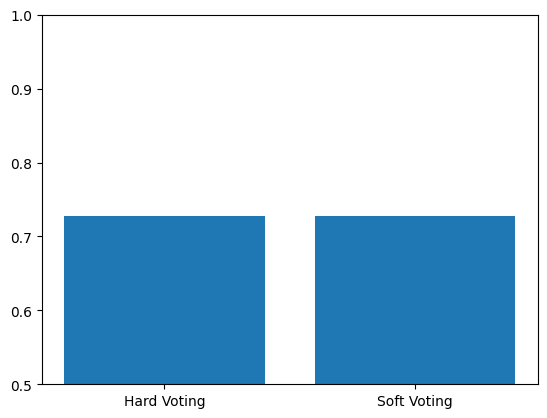

In [105]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (VotingClassifier, BaggingClassifier, RandomForestClassifier, AdaBoostClassifier)
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Redefining X and y using the correct 'Class' target column
X = df.drop(columns=['Class', 'Outcome'])
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

preprocessor.transformers[0] = ("scaler", preprocessor.transformers[0][1], X.columns.tolist())

estimators = [
    ("lr",  LogisticRegression(max_iter=1000, random_state=42)),
    ("svc", SVC(probability=True, random_state=42)),
    ("dt",  DecisionTreeClassifier(max_depth=5, random_state=42)),
]

hard = make_pipe(VotingClassifier(estimators, voting="hard")).fit(X_train, y_train)
soft = make_pipe(VotingClassifier(estimators, voting="soft")).fit(X_train, y_train)


hard_acc, soft_acc = hard.score(X_test, y_test), soft.score(X_test, y_test)
print(f"Hard Voting: {hard_acc:.4f}  |  Soft Voting: {soft_acc:.4f}")
print(classification_report(y_test, soft.predict(X_test)))

plt.bar(["Hard Voting","Soft Voting"], [hard_acc, soft_acc])
plt.ylim(0.5, 1)

Task 6: Bagging + Plt

OOB: 0.7492  |  Test: 0.7273



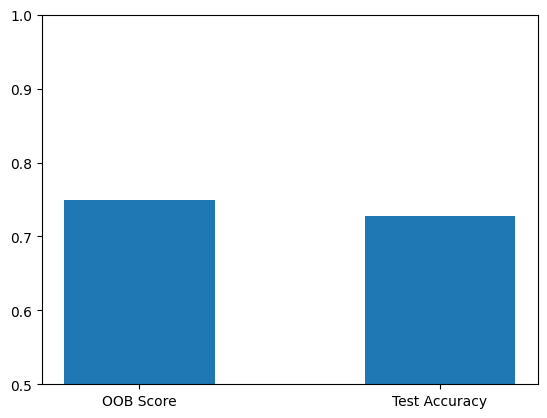

In [106]:
bag = make_pipe(BaggingClassifier(
    DecisionTreeClassifier(),
    n_estimators=100, oob_score=True,
    random_state=42, n_jobs=-1)).fit(X_train, y_train)

oob = bag.named_steps["model"].oob_score_
test = bag.score(X_test, y_test)
print(f"OOB: {oob:.4f}  |  Test: {test:.4f}\n")


plt.bar(["OOB Score", "Test Accuracy"], [oob, test], width=0.5)
plt.ylim(0.5, 1.0)
plt.show()

Task 7:

Random Forest Accuracy: 0.7338
              precision    recall  f1-score   support

           0       0.77      0.84      0.80       100
           1       0.64      0.54      0.59        54

    accuracy                           0.73       154
   macro avg       0.71      0.69      0.69       154
weighted avg       0.73      0.73      0.73       154



<Axes: >

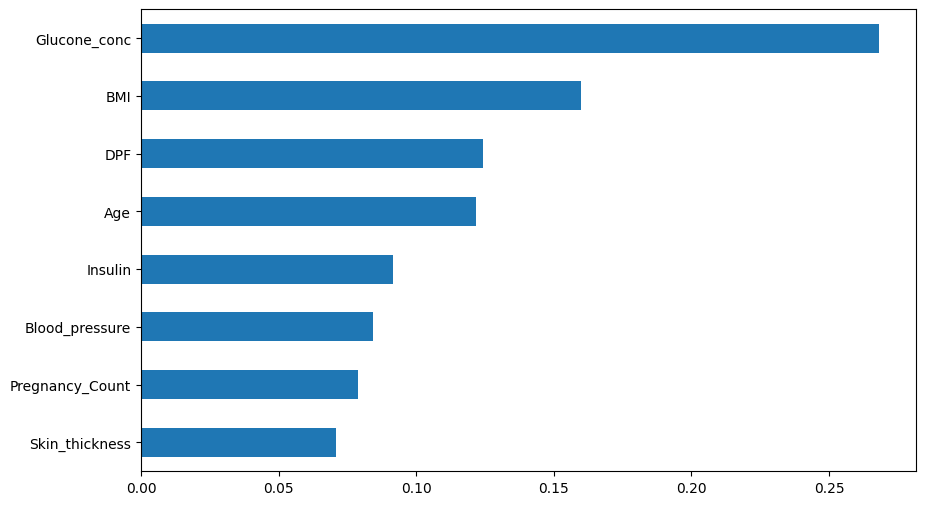

In [107]:
rf = make_pipe(RandomForestClassifier(
    n_estimators=300, max_features="sqrt",
    random_state=42, n_jobs=-1)).fit(X_train, y_train)

rf_acc = rf.score(X_test, y_test)
print(f"Random Forest Accuracy: {rf_acc:.4f}")
print(classification_report(y_test, rf.predict(X_test)))

imp = pd.Series(rf.named_steps["model"].feature_importances_, index=X.columns)
imp.sort_values().plot.barh(figsize=(10, 6))

Task 8:

Train: 0.7980  |  Test: 0.7468



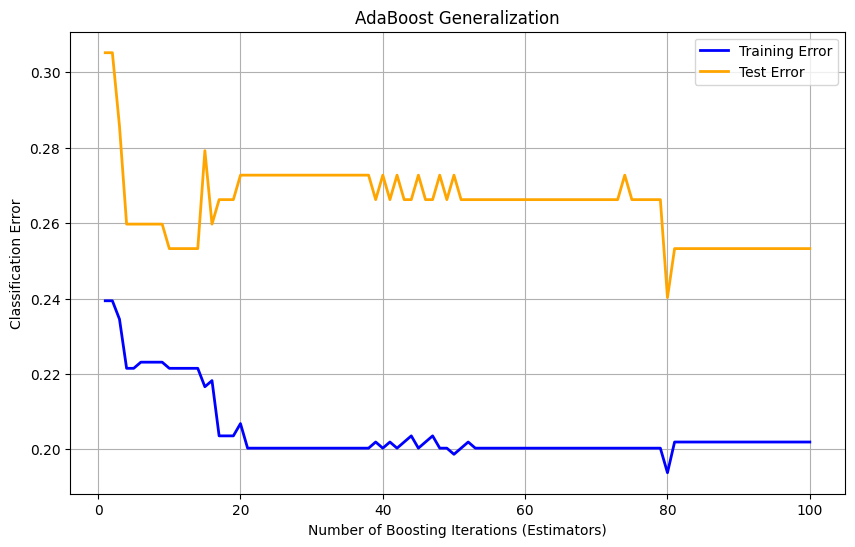

In [117]:
ada = make_pipe(AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=100, learning_rate=0.5,
    random_state=42)).fit(X_train, y_train)

print(f"Train: {ada.score(X_train, y_train):.4f}  |  Test: {ada.score(X_test, y_test):.4f}\n")

# Extract the AdaBoost model from the pipeline
ada_model = ada.named_steps["model"]

# Transform inputs using the pipeline's preprocessor step
X_train_trans = ada.named_steps["preprocessor"].transform(X_train)
X_test_trans = ada.named_steps["preprocessor"].transform(X_test)

train_errors = []
for score in ada_model.staged_score(X_train_trans, y_train): train_errors.append(1 - score)

test_errors = []
for score in ada_model.staged_score(X_test_trans, y_test): test_errors.append(1 - score)


plt.figure(figsize=(10, 6))
plt.plot(range(1, 101), train_errors, label="Training Error", color="blue", lw=2)
plt.plot(range(1, 101), test_errors, label="Test Error", color="orange", lw=2)
plt.xlabel("Number of Boosting Iterations (Estimators)")
plt.ylabel("Classification Error")
plt.title("AdaBoost Generalization")
plt.legend()
plt.grid(True)
plt.show()